<a href="https://colab.research.google.com/github/PP2909/Airbnb_listings_EDA/blob/main/Airbnb_Listings_EDA.ipynb" target="_parent">
<img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

In [1]:
from google.colab import files

uploaded = files.upload()


Saving airbnb_listings_eda_synthetic.csv to airbnb_listings_eda_synthetic.csv


In [16]:
# Check notebook-related files and GitHub configuration
import os

for root, dirs, files in os.walk('/content'):
    for file in files:
        if file.endswith(('.ipynb', '.md', '.py', '.html')):
            path = os.path.join(root, file)
            try:
                with open(path, 'r', encoding='utf-8') as f:
                    content = f.read()

                if 'YOUR_USERNAME' in content or 'YOUR_REPO' in content:
                    print("Found placeholder in:", path)
            except Exception:
                pass

In [2]:
import pandas as pd

file_name = list(uploaded.keys())[0]

df = pd.read_csv(file_name)

df.head()

,listing_id,host_id,city,neighbourhood,room_type,price,currency,minimum_nights,number_of_reviews,reviews_per_month,last_review,review_score,host_listings_count,accommodates,bedrooms,beds,availability_365
0,AB500001,10261,Barcelona,Gràcia,Entire home/apt,103.57,EUR,7,2,0.16,2026-09-11,NaN,2.0,5,2.0,4.0,140
1,AB500002,10247,London,Hackney,Entire home/apt,96.92,GBP,2,8,0.57,2025-09-19,4.19,3.0,7,1.0,2.0,256
2,AB500003,10462,New York,Staten Island,Private room,57.92,USD,1,3,0.17,2025-06-09,4.60,7.0,1,2.0,4.0,285
3,AB500004,10007,London,Camden,Private room,40.01,GBP,5,3,0.19,2026-05-10,4.20,5.0,1,1.0,1.0,90
4,AB500005,10098,Sydney,CBD,Shared room,41.93,AUD,1,8,0.84,2025-09-14,4.72,6.0,1,0.0,1.0,221


In [3]:
# understanding the given dataset

print("Dataset shape:", df.shape)

df.tail()

print("Number of rows:", df.shape[0])

print("Number of columns:", df.shape[1])

df.columns

df.info()

df.dtypes

df.describe()

numerical_columns = df.select_dtypes(include='number').columns

categorical_columns = df.select_dtypes(include='object').columns

print("Numerical Columns:")
print(list(numerical_columns))

print("\nCategorical Columns:")
print(list(categorical_columns))

Dataset shape: (2000, 17)
Number of rows: 2000
Number of columns: 17
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   listing_id           2000 non-null   object 
 1   host_id              2000 non-null   int64  
 2   city                 2000 non-null   object 
 3   neighbourhood        1976 non-null   object 
 4   room_type            2000 non-null   object 
 5   price                2000 non-null   float64
 6   currency             2000 non-null   object 
 7   minimum_nights       2000 non-null   int64  
 8   number_of_reviews    2000 non-null   int64  
 9   reviews_per_month    1937 non-null   float64
 10  last_review          1937 non-null   object 
 11  review_score         1697 non-null   float64
 12  host_listings_count  1980 non-null   float64
 13  accommodates         2000 non-null   int64  
 14  bedrooms           

In [4]:
# cleaning the above data

df.isnull().sum()

# listings with 0 reviews have no review data, so fill these with 0
df['reviews_per_month'] = df['reviews_per_month'].fillna(0)

# missing neighbourhood is labelled Unknown
df['neighbourhood'] = df['neighbourhood'].fillna('Unknown')

# last_review is a date, so it is not needed for the analysis
df = df.drop(columns=['last_review'])

for col in df.select_dtypes(include='number').columns:
    df[col] = df[col].fillna(df[col].median())

for col in df.select_dtypes(include='object').columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

df.duplicated().sum()

df.isnull().sum().sum()

np.int64(0)

In [5]:
# price is in local currency (one currency per city), so prices
# cannot be compared across cities directly.
# price_index = price divided by the median price of that city

df['price_index'] = df['price'] / df.groupby('city')['price'].transform('median')

df[['city', 'currency', 'price', 'price_index']].head()

,city,currency,price,price_index
0,Barcelona,EUR,103.57,1.412960
1,London,GBP,96.92,1.030516
2,New York,USD,57.92,0.500951
3,London,GBP,40.01,0.425412
4,Sydney,AUD,41.93,0.412737


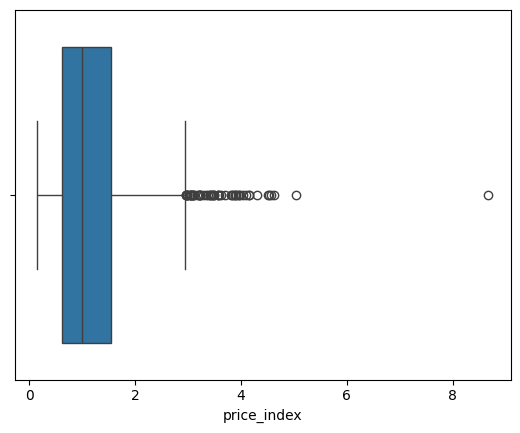

In [6]:
# outlier detection

Q1 = df.select_dtypes(include='number').quantile(0.25)
Q3 = df.select_dtypes(include='number').quantile(0.75)

IQR = Q3 - Q1

outliers = ((df.select_dtypes(include='number') < (Q1 - 1.5 * IQR)) |
            (df.select_dtypes(include='number') > (Q3 + 1.5 * IQR)) )

outliers.sum()

import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(x=df['price_index'])
plt.show()

# Price outliers look like genuine luxury listings, so they are kept.

In [7]:
# identify patterns

df.describe()

# 1. Entire homes make up most of the listings.
# 2. Price index has a long right tail (a few very expensive listings).
# 3. Review score and availability vary a lot between listings.

df['room_type'].value_counts()

df['city'].value_counts()

# Room type and city counts show how the listings are spread across the dataset.

,count
city,
New York,395
Paris,300
London,290
Barcelona,262
Tokyo,238
Dubai,218
Singapore,152
Sydney,145


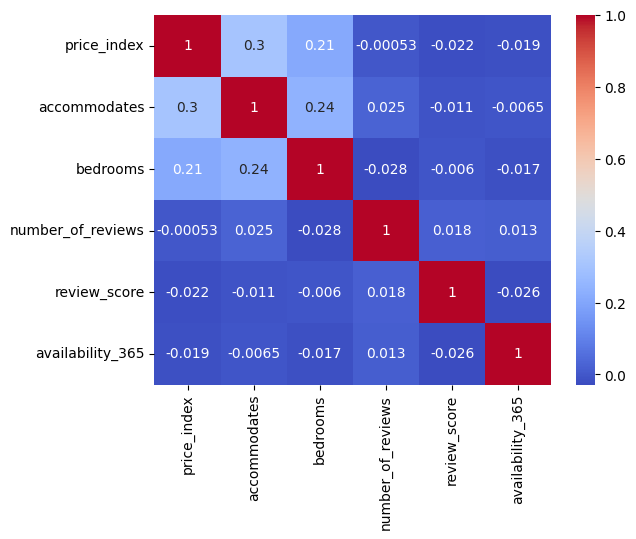

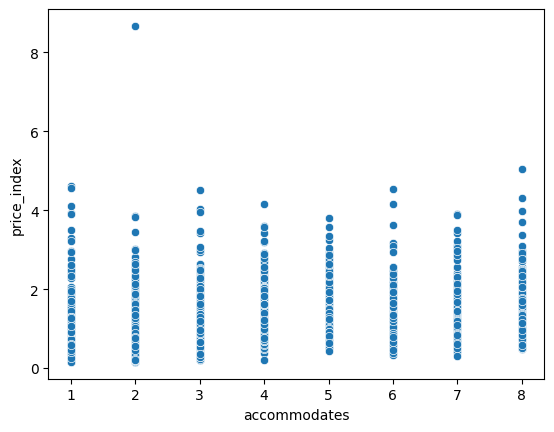

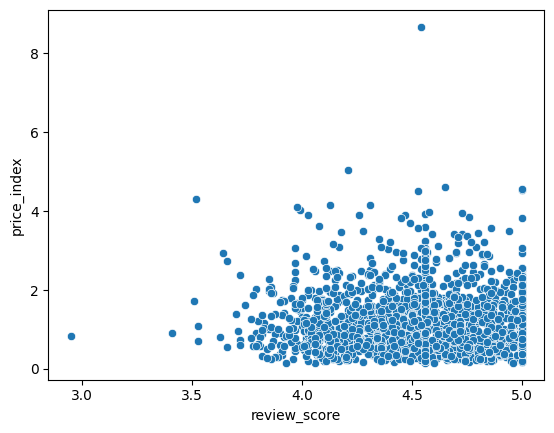

In [8]:
# understanding relationships
cols = ['price_index', 'accommodates', 'bedrooms',
        'number_of_reviews', 'review_score', 'availability_365']

df[cols].corr()

sns.heatmap(df[cols].corr(), annot=True, cmap='coolwarm')
plt.show()

sns.scatterplot(data=df, x='accommodates', y='price_index')
plt.show()

sns.scatterplot(data=df, x='review_score', y='price_index')
plt.show()

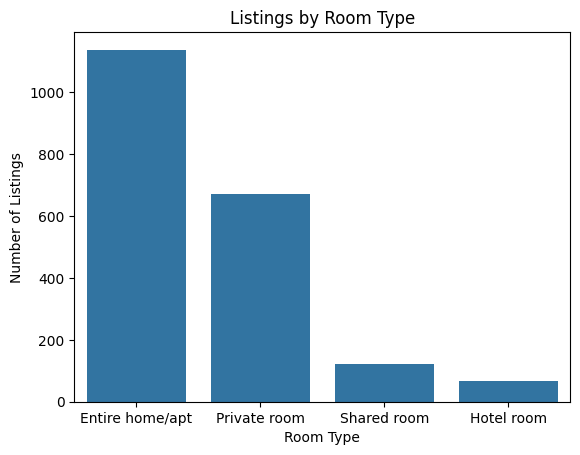

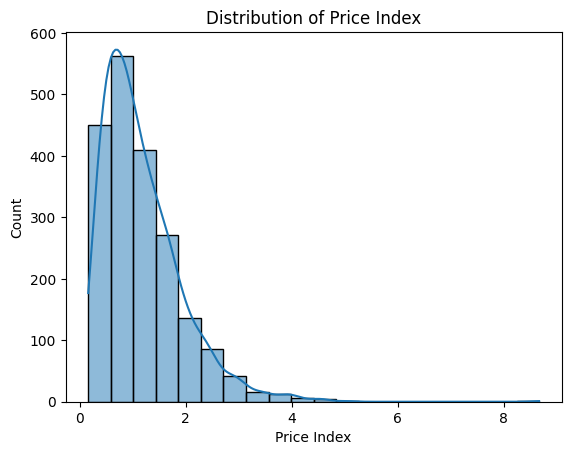

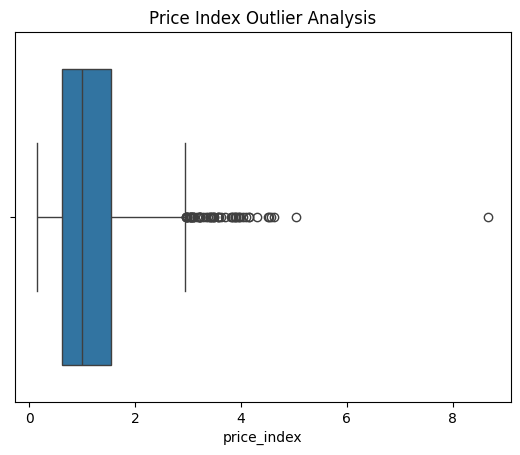

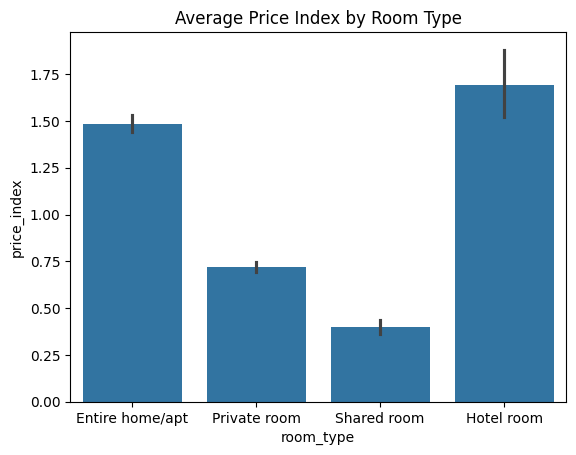

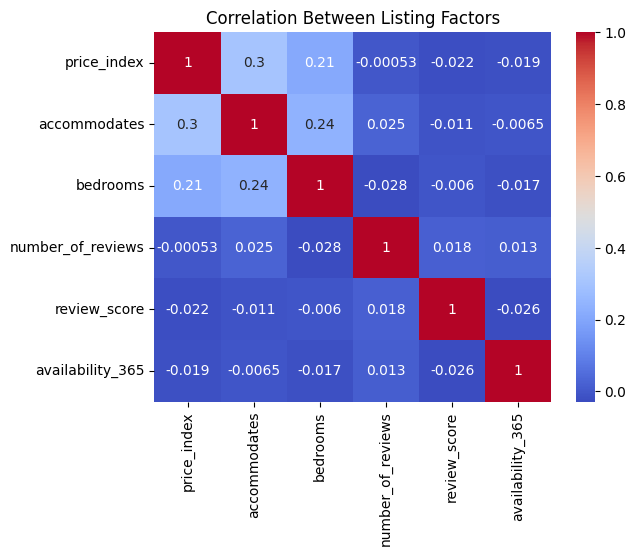

In [9]:
# data visualization
sns.countplot(data=df, x='room_type')
plt.title('Listings by Room Type')
plt.xlabel('Room Type')
plt.ylabel('Number of Listings')
plt.show()

sns.histplot(df['price_index'], bins=20, kde=True)
plt.title('Distribution of Price Index')
plt.xlabel('Price Index')
plt.show()

sns.boxplot(x=df['price_index'])
plt.title('Price Index Outlier Analysis')
plt.show()

sns.barplot(data=df, x='room_type', y='price_index')
plt.title('Average Price Index by Room Type')
plt.show()

sns.heatmap(df[cols].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Between Listing Factors')
plt.show()

In [10]:
# prepare dataset for ml
X = df.drop(columns=['price', 'price_index', 'currency',
                     'listing_id', 'host_id'], errors='ignore')

y = df['price_index']

X = pd.get_dummies(X, drop_first=True, dtype=int)

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

X_train.shape, X_test.shape

((1600, 59), (400, 59))